In [1]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\skampure\Desktop\Quant finance\Quant Research\.venv\Scripts\python.exe
3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]


In [2]:
import yfinance as yf
import pandas as pd

spy = yf.download(
    "SPY",
    start="2000-01-01",
    end="2026-08-01",
    auto_adjust=False
)

spy.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY,SPY
Date,,,,,,
2000-01-03,90.906998,145.4375,148.25000,143.875000,148.25000,8164300
2000-01-04,87.352013,139.7500,144.06250,139.640625,143.53125,8089800
2000-01-05,87.508240,140.0000,141.53125,137.250000,139.93750,12177900
2000-01-06,86.101883,137.7500,141.50000,137.750000,139.62500,6227200
2000-01-07,91.102364,145.7500,145.75000,140.062500,140.31250,8066500


In [3]:
spy[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].tail()

Price,Open,High,Low,Close,Adj Close,Volume
Ticker,SPY,SPY,SPY,SPY,SPY,SPY
Date,,,,,,
2026-07-27,744.909973,745.530029,735.869995,739.090027,737.259277,41461200
2026-07-28,739.190002,742.789978,735.979980,740.859985,739.024841,47322200
2026-07-29,739.969971,742.679993,729.099976,729.460022,727.653137,70697200
2026-07-30,736.049988,742.450012,734.590027,741.690002,739.852783,66811300
2026-07-31,744.679993,748.900024,737.679993,747.030029,745.179626,62445900


In [4]:
spy["Volume"].describe()

Ticker,SPY
count,6.684000e+03
mean,1.040294e+08
std,8.889018e+07
min,1.436600e+06
25%,5.052850e+07
50%,7.730350e+07
75%,1.299566e+08
max,8.710263e+08


In [5]:
spy["Adj Close"].describe()

Ticker,SPY
count,6684.000000
mean,206.059600
std,167.650668
min,49.557510
25%,84.656557
50%,125.398582
75%,269.813141
max,755.741577


In [6]:
spy["Return"] = spy["Adj Close"].pct_change()
spy[["Adj Close", "Return"]].tail()

Price,Adj Close,Return
Ticker,SPY,
Date,,
2026-07-27,737.259277,0.000217
2026-07-28,739.024841,0.002395
2026-07-29,727.653137,-0.015387
2026-07-30,739.852783,0.016766
2026-07-31,745.179626,0.007200


In [7]:
spy["Return"].describe()

count    6683.000000
mean        0.000389
std         0.012151
min        -0.109424
25%        -0.004590
50%         0.000693
75%         0.005991
max         0.145198
Name: Return, dtype: float64

<Axes: >

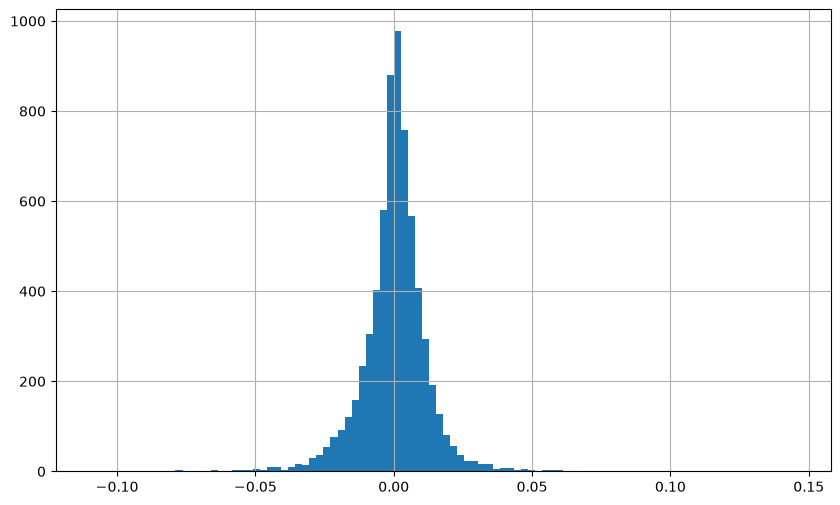

In [8]:
spy["Return"].hist(bins=100, figsize=(10, 6))

In [9]:
spy["Return"].mean()

np.float64(0.00038868537556306583)

In [10]:
spy["Return"].std()
spy["Return"].skew()

np.float64(0.04016843825141744)

In [11]:
spy["Return"].skew()

np.float64(0.04016843825141744)

In [12]:
spy["Return"].kurt()

np.float64(12.059911499209626)

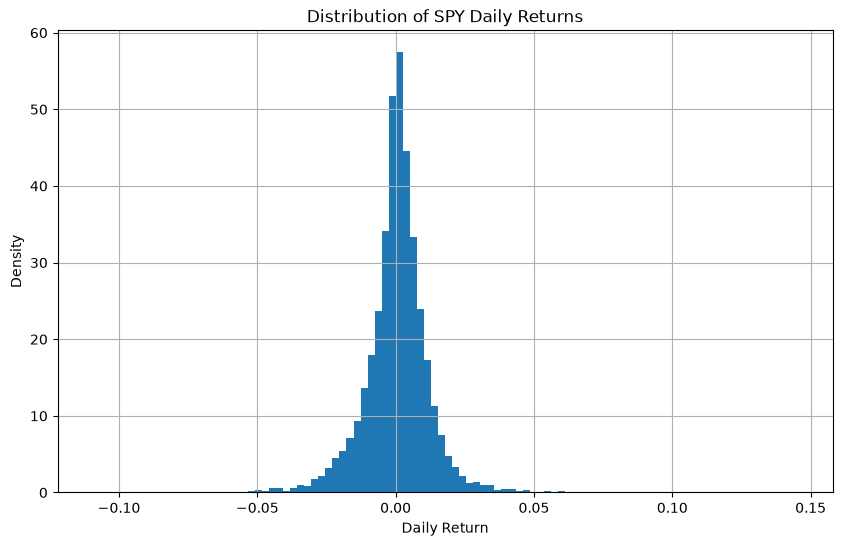

In [13]:
import matplotlib.pyplot as plt

spy["Return"].hist(
    bins=100,
    density=True,
    figsize=(10, 6)
)

plt.title("Distribution of SPY Daily Returns")
plt.xlabel("Daily Return")
plt.ylabel("Density")
plt.show()

In [14]:
print("Mean:", spy["Return"].mean())
print("Std:", spy["Return"].std())
print("Skewness:", spy["Return"].skew())
print("Excess Kurtosis:", spy["Return"].kurt())

Mean: 0.00038868537556306583
Std: 0.01215110637097585
Skewness: 0.04016843825141744
Excess Kurtosis: 12.059911499209626


In [15]:
spy["Return"].sort_values().head(10)

Date
2020-03-16   -0.109424
2008-10-15   -0.098447
2020-03-12   -0.095677
2008-12-01   -0.088578
2008-09-29   -0.078362
2020-03-09   -0.078094
2008-11-20   -0.074233
2008-10-09   -0.069839
2011-08-08   -0.065123
2008-11-19   -0.064079
Name: Return, dtype: float64

In [16]:
spy["Return"].sort_values(ascending=False).head(10)

Date
2008-10-13    0.145198
2008-10-28    0.116855
2025-04-09    0.105019
2020-03-24    0.090603
2020-03-13    0.085486
2009-03-23    0.071829
2008-11-24    0.069290
2020-04-06    0.067166
2008-11-13    0.062340
2008-10-20    0.060079
Name: Return, dtype: float64

In [17]:
rolling_vol = spy["Return"].rolling(window=30).std()

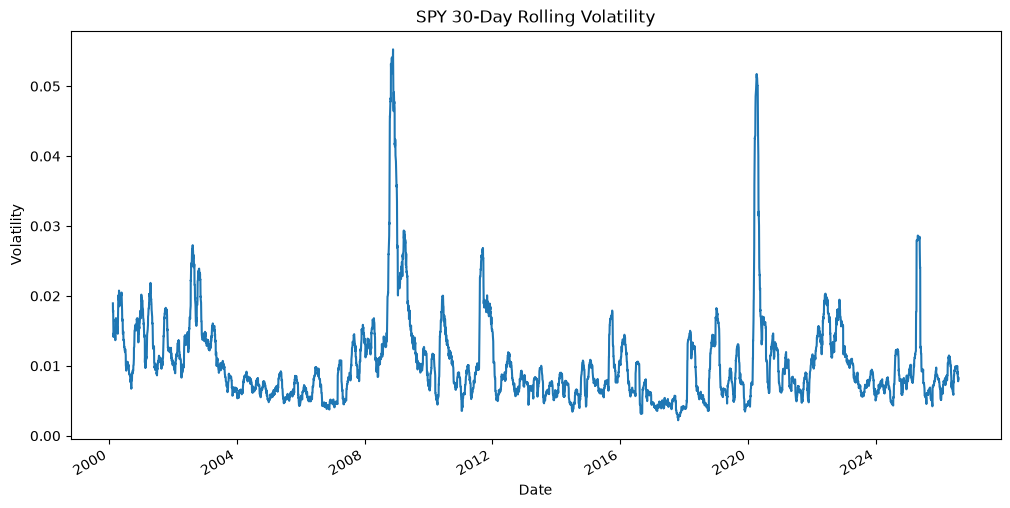

In [18]:
import matplotlib.pyplot as plt

rolling_vol.plot(figsize=(12, 6))

plt.title("SPY 30-Day Rolling Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.show()

In [19]:
rolling_vol_pct = rolling_vol * 100

In [20]:
rolling_vol_pct.describe()

count    6654.000000
mean        1.035133
std         0.644638
min         0.221484
25%         0.643309
50%         0.850614
75%         1.249425
max         5.526849
Name: Return, dtype: float64

In [21]:
rolling_vol_pct.sort_values(ascending=False).head(10)

Date
2008-11-21    5.526849
2008-11-20    5.437026
2008-11-19    5.418215
2008-11-14    5.414933
2008-11-07    5.407584
2008-11-06    5.356939
2008-11-13    5.355121
2008-11-17    5.352030
2008-10-28    5.320675
2008-11-18    5.316512
Name: Return, dtype: float64

In [22]:
rolling_vol_pct.loc["2008":"2009"].describe()

count    505.000000
mean       1.884222
std        1.154685
min        0.708973
25%        1.163273
50%        1.381070
75%        2.287120
max        5.526849
Name: Return, dtype: float64

In [23]:
rolling_vol_pct.loc["2020"].describe()

count    253.000000
mean       1.686203
std        1.267935
min        0.415632
25%        0.886358
50%        1.296091
75%        1.655000
max        5.174227
Name: Return, dtype: float64

In [24]:
spy["Abs_Return"] = spy["Return"].abs()

In [25]:
autocorr_abs = spy["Abs_Return"].autocorr(lag=1)

print("Lag-1 autocorrelation of absolute returns:", autocorr_abs)

Lag-1 autocorrelation of absolute returns: 0.28948840305028967


In [26]:
for lag in range(1, 11):
    autocorr = spy["Abs_Return"].autocorr(lag=lag)
    print(f"Lag {lag}: {autocorr:.4f}")

Lag 1: 0.2895
Lag 2: 0.3766
Lag 3: 0.3250
Lag 4: 0.3317
Lag 5: 0.3371
Lag 6: 0.3194
Lag 7: 0.3123
Lag 8: 0.3036
Lag 9: 0.2899
Lag 10: 0.2957


In [27]:
spy = spy.dropna(subset=["Return"])

train = spy.loc[: "2018-12-31"].copy()
test = spy.loc["2019-01-01":].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

KeyError: ['Return']

In [ ]:
spy.columns

MultiIndex([( 'Adj Close', 'SPY'),
            (     'Close', 'SPY'),
            (      'High', 'SPY'),
            (       'Low', 'SPY'),
            (      'Open', 'SPY'),
            (    'Volume', 'SPY'),
            (    'Return',    ''),
            ('Abs_Return',    '')],
           names=['Price', 'Ticker'])

In [ ]:
spy.head()

Price,Adj Close,Close,High,Low,Open,Volume,Return,Abs_Return
Ticker,SPY,SPY,SPY,SPY,SPY,SPY,,
Date,,,,,,,,
2000-01-03,91.132736,145.4375,148.25000,143.875000,148.25000,8164300,NaN,NaN
2000-01-04,87.568916,139.7500,144.06250,139.640625,143.53125,8089800,-0.039106,0.039106
2000-01-05,87.725555,140.0000,141.53125,137.250000,139.93750,12177900,0.001789,0.001789
2000-01-06,86.315697,137.7500,141.50000,137.750000,139.62500,6227200,-0.016071,0.016071
2000-01-07,91.328552,145.7500,145.75000,140.062500,140.31250,8066500,0.058076,0.058076


In [ ]:
print(spy.index.min())
print(spy.index.max())

2000-01-03 00:00:00
2026-07-31 00:00:00


In [ ]:
print(spy["Return"].head())

Date
2000-01-03         NaN
2000-01-04   -0.039106
2000-01-05    0.001789
2000-01-06   -0.016071
2000-01-07    0.058076
Name: Return, dtype: float64


In [ ]:
spy = spy.iloc[1:].copy()

In [ ]:
train = spy.loc[: "2018-12-31"].copy()
test = spy.loc["2019-01-01":].copy()

In [ ]:
print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 4778
Testing observations: 1905


In [ ]:
print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Training period: 2000-01-04 00:00:00 to 2018-12-31 00:00:00
Testing period: 2019-01-02 00:00:00 to 2026-07-31 00:00:00


In [ ]:
train_returns = train["Return"]

In [ ]:
print(train_returns.head())
print(train_returns.shape)

Date
2000-01-04   -0.039106
2000-01-05    0.001789
2000-01-06   -0.016071
2000-01-07    0.058076
2000-01-10    0.003431
Name: Return, dtype: float64
(4778,)


In [ ]:
train_returns_pct = train_returns * 100

In [ ]:
from arch import arch_model

In [ ]:
model = arch_model(
    train_returns_pct,
    vol="Garch",
    p=1,
    q=1,
    mean="Constant"
)

results = model.fit()

print(results.summary())

Iteration:      1,   Func. Count:      6,   Neg. LLF: 6085195475.231981
Iteration:      2,   Func. Count:     15,   Neg. LLF: 188983318.0222685
Iteration:      3,   Func. Count:     22,   Neg. LLF: 9229.066370670193
Iteration:      4,   Func. Count:     29,   Neg. LLF: 6641.280636555919
Iteration:      5,   Func. Count:     35,   Neg. LLF: 6566.710999155219
Iteration:      6,   Func. Count:     41,   Neg. LLF: 6772.6475868720645
Iteration:      7,   Func. Count:     47,   Neg. LLF: 6547.201170070768
Iteration:      8,   Func. Count:     53,   Neg. LLF: 6530.334219267428
Iteration:      9,   Func. Count:     58,   Neg. LLF: 6530.196879772502
Iteration:     10,   Func. Count:     63,   Neg. LLF: 6530.195421068209
Iteration:     11,   Func. Count:     68,   Neg. LLF: 6530.195402331431
Iteration:     12,   Func. Count:     73,   Neg. LLF: 6530.195401805321
Optimization terminated successfully    (Exit mode 0)
            Current function value: 6530.195401805321
            Iterations: 12


In [ ]:
print(results.params)

mu          0.065609
omega       0.019420
alpha[1]    0.110344
beta[1]     0.875009
Name: params, dtype: float64


In [ ]:
print(results.pvalues)

mu          9.836718e-09
omega       6.907523e-05
alpha[1]    2.546698e-16
beta[1]     0.000000e+00
Name: pvalues, dtype: float64


In [ ]:
print(results.conf_int())

             lower     upper
mu        0.043181  0.088037
omega     0.009855  0.028985
alpha[1]  0.083948  0.136741
beta[1]   0.847773  0.902246


In [ ]:
conditional_volatility = results.conditional_volatility

print(conditional_volatility.head())
print()
print(conditional_volatility.describe())

In [ ]:
print(spy.columns)

MultiIndex([( 'Adj Close', 'SPY'),
            (     'Close', 'SPY'),
            (      'High', 'SPY'),
            (       'Low', 'SPY'),
            (      'Open', 'SPY'),
            (    'Volume', 'SPY'),
            (    'Return',    ''),
            ('Abs_Return',    '')],
           names=['Price', 'Ticker'])


In [ ]:
spy = spy.dropna(subset=[("Return", "")])

train = spy.loc[: "2018-12-31"].copy()
test = spy.loc["2019-01-01":].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 4778
Testing observations: 1905


In [ ]:
spy.columns = [
    col[0] if col[1] == "" else col[0]
    for col in spy.columns
]

print(spy.columns)

Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Return',
       'Abs_Return'],
      dtype='str')


In [ ]:
conditional_volatility = results.conditional_volatility

print(conditional_volatility.head())
print()
print(conditional_volatility.describe())

NameError: name 'results' is not defined

In [ ]:
train_returns_pct = train["Return"] * 100

In [ ]:
print(train_returns_pct.head())
print(train_returns_pct.describe())

Date
2000-01-04   -3.910632
2000-01-05    0.178909
2000-01-06   -1.607113
2000-01-07    5.807632
2000-01-10    0.342987
Name: Return, dtype: float64
count    4778.000000
mean        0.026129
std         1.212536
min        -9.844766
25%        -0.473520
50%         0.063079
75%         0.578856
max        14.519796
Name: Return, dtype: float64


In [ ]:
from arch import arch_model

model = arch_model(
    train_returns_pct,
    vol="Garch",
    p=1,
    q=1,
    mean="Constant"
)

results = model.fit()

print(results.summary())

Iteration:      1,   Func. Count:      6,   Neg. LLF: 316833339514678.4
Iteration:      2,   Func. Count:     15,   Neg. LLF: 1251253126.2793796
Iteration:      3,   Func. Count:     22,   Neg. LLF: 9229.02976760544
Iteration:      4,   Func. Count:     29,   Neg. LLF: 6641.284682827023
Iteration:      5,   Func. Count:     35,   Neg. LLF: 6566.709343228022
Iteration:      6,   Func. Count:     41,   Neg. LLF: 6772.650266576713
Iteration:      7,   Func. Count:     47,   Neg. LLF: 6547.205728336687
Iteration:      8,   Func. Count:     53,   Neg. LLF: 6530.337114560381
Iteration:      9,   Func. Count:     58,   Neg. LLF: 6530.199726610093
Iteration:     10,   Func. Count:     63,   Neg. LLF: 6530.198267759239
Iteration:     11,   Func. Count:     68,   Neg. LLF: 6530.198249026539
Iteration:     12,   Func. Count:     73,   Neg. LLF: 6530.198248501121
Optimization terminated successfully    (Exit mode 0)
            Current function value: 6530.198248501121
            Iterations: 12
 

In [ ]:
conditional_volatility = results.conditional_volatility

print(conditional_volatility.head())
print()
print(conditional_volatility.describe())

Date
2000-01-04    2.071088
2000-01-05    2.348892
2000-01-06    2.201935
2000-01-07    2.137910
2000-01-10    2.767118
Name: cond_vol, dtype: float64

count    4778.000000
mean        1.053321
std         0.588284
min         0.431754
25%         0.678741
50%         0.895672
75%         1.238948
max         6.184101
Name: cond_vol, dtype: float64


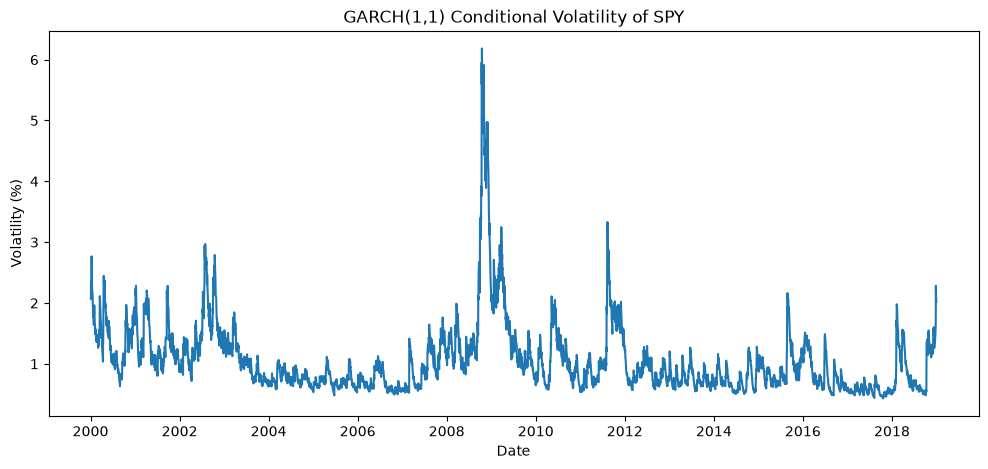

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(conditional_volatility)

plt.title("GARCH(1,1) Conditional Volatility of SPY")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")

plt.show()

In [ ]:
forecast = results.forecast(horizon=1)

print(forecast.variance.tail())

                 h.1
Date                
2018-12-31  3.660755


In [ ]:
forecast_variance = forecast.variance.iloc[-1, 0]

forecast_volatility = forecast_variance ** 0.5

print("Forecasted variance:", forecast_variance)
print("Forecasted volatility:", forecast_volatility, "%")

Forecasted variance: 3.6607550902708117
Forecasted volatility: 1.9133099827970406 %


In [ ]:
conditional_volatility = results.conditional_volatility

print(conditional_volatility.describe())

count    4778.000000
mean        1.053321
std         0.588284
min         0.431754
25%         0.678741
50%         0.895672
75%         1.238948
max         6.184101
Name: cond_vol, dtype: float64


In [ ]:
forecast = results.forecast(horizon=1)

forecast_variance = forecast.variance.iloc[-1, 0]
forecast_volatility = forecast_variance ** 0.5

print("Forecasted variance:", forecast_variance)
print("Forecasted volatility:", forecast_volatility, "%")

Forecasted variance: 3.6607550902708117
Forecasted volatility: 1.9133099827970406 %


In [ ]:
forecast = results.forecast(
    horizon=len(test),
    reindex=False
)

print(forecast.variance)

              h.0001    h.0002    h.0003    h.0004    h.0005    h.0006  \
Date                                                                     
2018-12-31  3.660755  3.626558  3.592862  3.559659  3.526943  3.494706   

              h.0007    h.0008  h.0009   h.0010  ...   h.1896   h.1897  \
Date                                             ...                     
2018-12-31  3.462941  3.431641  3.4008  3.37041  ...  1.32595  1.32595   

             h.1898   h.1899   h.1900   h.1901   h.1902   h.1903   h.1904  \
Date                                                                        
2018-12-31  1.32595  1.32595  1.32595  1.32595  1.32595  1.32595  1.32595   

             h.1905  
Date                 
2018-12-31  1.32595  

[1 rows x 1905 columns]


In [ ]:
forecast = results.forecast(
    horizon=1,
    start="2018-12-31",
    reindex=False
)

print(forecast.variance.tail())

                 h.1
Date                
2018-12-31  3.660755


In [ ]:
forecast_variance = 3.660755
forecast_volatility = forecast_variance ** 0.5

print("Forecasted variance:", forecast_variance)
print("Forecasted volatility:", forecast_volatility, "%")

Forecasted variance: 3.660755
Forecasted volatility: 1.9133099592068192 %


In [ ]:
forecast = results.forecast(
    horizon=30,
    reindex=False
)

forecast_variance = forecast.variance.iloc[-1]

print(forecast_variance)

h.01    3.660755
h.02    3.626558
h.03    3.592862
h.04    3.559659
h.05    3.526943
h.06    3.494706
h.07    3.462941
h.08    3.431641
h.09    3.400800
h.10    3.370410
h.11    3.340466
h.12    3.310960
h.13    3.281887
h.14    3.253239
h.15    3.225010
h.16    3.197196
h.17    3.169788
h.18    3.142782
h.19    3.116172
h.20    3.089951
h.21    3.064114
h.22    3.038656
h.23    3.013571
h.24    2.988853
h.25    2.964497
h.26    2.940498
h.27    2.916850
h.28    2.893549
h.29    2.870589
h.30    2.847965
Name: 2018-12-31 00:00:00, dtype: float64


In [ ]:
import numpy as np
import pandas as pd

# Get the 30-day variance forecast
forecast = results.forecast(
    horizon=30,
    reindex=False
)

forecast_variance = forecast.variance.iloc[-1]

# Convert variance to volatility
forecast_volatility = np.sqrt(forecast_variance)

# Put everything into a DataFrame
forecast_df = pd.DataFrame({
    "Variance": forecast_variance,
    "Volatility (%)": forecast_volatility
})

print(forecast_df)

      Variance  Volatility (%)
h.01  3.660755        1.913310
h.02  3.626558        1.904352
h.03  3.592862        1.895485
h.04  3.559659        1.886706
h.05  3.526943        1.878016
h.06  3.494706        1.869413
h.07  3.462941        1.860898
h.08  3.431641        1.852469
h.09  3.400800        1.844126
h.10  3.370410        1.835868
h.11  3.340466        1.827694
h.12  3.310960        1.819604
h.13  3.281887        1.811598
h.14  3.253239        1.803674
h.15  3.225010        1.795831
h.16  3.197196        1.788070
h.17  3.169788        1.780390
h.18  3.142782        1.772789
h.19  3.116172        1.765268
h.20  3.089951        1.757826
h.21  3.064114        1.750461
h.22  3.038656        1.743174
h.23  3.013571        1.735964
h.24  2.988853        1.728830
h.25  2.964497        1.721771
h.26  2.940498        1.714788
h.27  2.916850        1.707879
h.28  2.893549        1.701043
h.29  2.870589        1.694281
h.30  2.847965        1.687591


In [ ]:
omega = results.params["omega"]
alpha = results.params["alpha[1]"]
beta = results.params["beta[1]"]

long_run_variance = omega / (1 - alpha - beta)
long_run_volatility = np.sqrt(long_run_variance)

print("Long-run variance:", long_run_variance)
print("Long-run daily volatility (%):", long_run_volatility)

Long-run variance: 1.325950336636897
Long-run daily volatility (%): 1.1514991691863685


In [ ]:
test_returns_pct = test["Return"] * 100

print(test_returns_pct.head())
print()
print(test_returns_pct.describe())

Date
2019-01-02    0.104038
2019-01-03   -2.386260
2019-01-04    3.349573
2019-01-07    0.788475
2019-01-08    0.939506
Name: Return, dtype: float64

count    1905.000000
mean        0.070821
std         1.221278
min       -10.942390
25%        -0.427343
50%         0.098452
75%         0.663859
max        10.501922
Name: Return, dtype: float64


In [ ]:
omega = results.params["omega"]
alpha = results.params["alpha[1]"]
beta = results.params["beta[1]"]
mu = results.params["mu"]

print("mu =", mu)
print("omega =", omega)
print("alpha =", alpha)
print("beta =", beta)

mu = 0.06560857893922135
omega = 0.01942069496345991
alpha = 0.11034467124483169
beta = 0.8750087055545452


In [ ]:
# Store the forecasts
forecast_variances = []

# Start with the final conditional variance from the training period
previous_variance = results.conditional_volatility.iloc[-1] ** 2

# Start with the final training return
previous_return = train_returns_pct.iloc[-1]

for return_value in test_returns_pct:

    # Previous period's shock
    previous_residual = previous_return - mu

    # GARCH(1,1) one-step-ahead variance forecast
    forecast_variance = (
        omega
        + alpha * previous_residual**2
        + beta * previous_variance
    )

    forecast_variances.append(forecast_variance)

    # Once the actual return is observed,
    # use it for the next day's forecast
    previous_return = return_value
    previous_variance = forecast_variance

In [ ]:
forecast_volatility = np.sqrt(forecast_variances)

print(forecast_volatility[:10])

[1.91330998 1.79520924 1.87155882 2.06744906 1.95375776 1.85573356
 1.74657907 1.64248798 1.54274765 1.46710077]


In [ ]:
realized_variance = test_returns_pct**2

In [ ]:
evaluation = pd.DataFrame({
    "Return": test_returns_pct.values,
    "Realized_Variance": realized_variance.values,
    "Forecast_Variance": forecast_variances,
    "Forecast_Volatility": forecast_volatility
}, index=test.index)

print(evaluation.head())

              Return  Realized_Variance  Forecast_Variance  \
Date                                                         
2019-01-02  0.104038           0.010824           3.660755   
2019-01-03 -2.386260           5.694236           3.222776   
2019-01-04  3.349573          11.219639           3.502732   
2019-01-07  0.788475           0.621693           4.274346   
2019-01-08  0.939506           0.882672           3.817169   

            Forecast_Volatility  
Date                             
2019-01-02             1.913310  
2019-01-03             1.795209  
2019-01-04             1.871559  
2019-01-07             2.067449  
2019-01-08             1.953758  


In [ ]:
mse = np.mean(
    (evaluation["Forecast_Variance"]
     - evaluation["Realized_Variance"]) ** 2
)

print("MSE:", mse)

MSE: 26.6962857705858


In [ ]:
mae = np.mean(
    np.abs(
        evaluation["Forecast_Variance"]
        - evaluation["Realized_Variance"]
    )
)

print("MAE:", mae)

MAE: 1.5576349463239056


In [ ]:
qlike = np.mean(
    evaluation["Realized_Variance"]
    / evaluation["Forecast_Variance"]
    + np.log(evaluation["Forecast_Variance"])
)

print("QLIKE:", qlike)

QLIKE: 0.9393653262502464


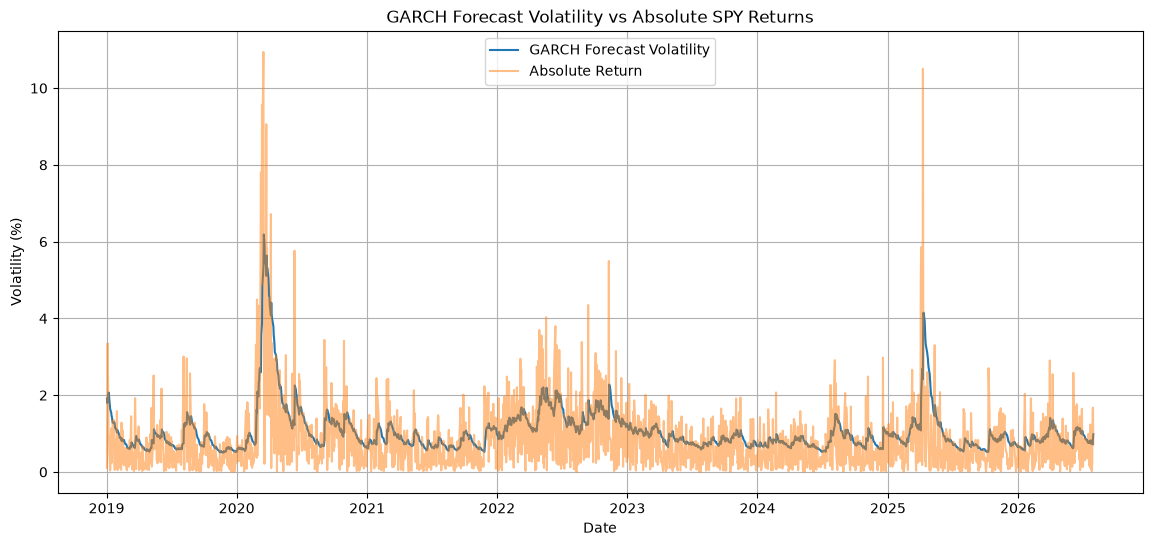

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    evaluation.index,
    evaluation["Forecast_Volatility"],
    label="GARCH Forecast Volatility"
)

plt.plot(
    evaluation.index,
    np.abs(evaluation["Return"]),
    label="Absolute Return",
    alpha=0.5
)

plt.title("GARCH Forecast Volatility vs Absolute SPY Returns")
plt.xlabel("Date")
plt.ylabel("Volatility (%)")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Combine training and test returns
all_returns = pd.concat([
    train_returns_pct,
    test_returns_pct
])

# 20-day rolling variance
rolling_variance = all_returns.rolling(20).var()

# Get the benchmark forecasts corresponding to the test period
benchmark_variance = rolling_variance.loc[test.index]

# Remove any missing values
benchmark_variance = benchmark_variance.dropna()

print(benchmark_variance.head())

Date
2019-01-02    3.388018
2019-01-03    3.387879
2019-01-04    3.744478
2019-01-07    3.802824
2019-01-08    3.622167
Name: Return, dtype: float64


In [ ]:
benchmark_mse = np.mean(
    (
        benchmark_variance.values
        - evaluation.loc[benchmark_variance.index, "Realized_Variance"].values
    ) ** 2
)

print("20-day rolling variance MSE:", benchmark_mse)

20-day rolling variance MSE: 28.269471911121197


In [ ]:
benchmark_qlike = np.mean(
    evaluation.loc[benchmark_variance.index, "Realized_Variance"].values
    / benchmark_variance.values
    + np.log(benchmark_variance.values)
)

print("20-day rolling variance QLIKE:", benchmark_qlike)

20-day rolling variance QLIKE: 0.8333668050647031


In [ ]:
from arch import arch_model

model_t = arch_model(
    train_returns_pct,
    vol="Garch",
    p=1,
    q=1,
    mean="Constant",
    dist="t"
)

results_t = model_t.fit()

print(results_t.summary())

Iteration:      1,   Func. Count:      7,   Neg. LLF: 157392.84081845958
Iteration:      2,   Func. Count:     18,   Neg. LLF: 77768.06224035146
Iteration:      3,   Func. Count:     26,   Neg. LLF: 12473.186991943174
Iteration:      4,   Func. Count:     34,   Neg. LLF: 11348.435578468398
Iteration:      5,   Func. Count:     41,   Neg. LLF: 6455.7716913222275
Iteration:      6,   Func. Count:     48,   Neg. LLF: 11060.721816629462
Iteration:      7,   Func. Count:     55,   Neg. LLF: 6428.194061899103
Iteration:      8,   Func. Count:     62,   Neg. LLF: 6448.672578624806
Iteration:      9,   Func. Count:     69,   Neg. LLF: 6425.406405828723
Iteration:     10,   Func. Count:     76,   Neg. LLF: 6423.317869961408
Iteration:     11,   Func. Count:     82,   Neg. LLF: 6423.263838275292
Iteration:     12,   Func. Count:     88,   Neg. LLF: 6423.223965454137
Iteration:     13,   Func. Count:     94,   Neg. LLF: 6423.210000885205
Iteration:     14,   Func. Count:    100,   Neg. LLF: 6423.

In [ ]:
print(results_t.params)

mu          0.078003
omega       0.010418
alpha[1]    0.112252
beta[1]     0.887078
nu          6.279953
Name: params, dtype: float64
